# SCORE-Net: Architecture, Regularization, and Proposition Validation

This notebook reproduces all ablation experiments from **Section 4.7: Ablation Studies and Sensitivity Analysis** of the SCORE-Net paper from training outputs and saves the `fig_ablation_synthetic.pdf` / `.png` figure.

### Two ablation axes

1. **Empirical architecture and regularization ablation (Synthetic, 20 classes, 30 features):**
   * Dual $L_1$ regularization ($L_1(W_f)$ and $L_1(W_o)$).
   * Dropout.
   * Initial capacity $H \in \{512, 1024, 2048\}$.
2. **Validation of Proposition 1 (Exact Bias Shifting):**
   * Only **structurally empty** rules are removed on the four benchmark datasets.
   * Bias shifting from Proposition 1 is compared with naive pruning (no correction).
   * Structural pruning ensures that the bias shift is the only difference between the two methods; empirical dead-rule cleanup is excluded from this experiment.

### Where do the numbers come from?

* Ablation checkpoints are loaded from `models/ablations/` and `models (Synthetic)/`.
* `H_init`, feature counts, and class counts are read directly from `state_dict` shapes.
* Rule counts, sparsity, and accuracies are computed from models compressed at runtime.
* No accuracy, rule count, or $H$ value is hard-coded in the notebook.

> **Run order:** all training notebooks (main models + `models/ablations`) → this notebook.

In [1]:
import copy
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Locate the project root regardless of the notebook's working directory.
cwd = Path.cwd().resolve()
project_root = next(
    (path for path in [cwd, *cwd.parents] if (path / "utils" / "experiments.py").exists()),
    cwd.parent,
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from utils.reproducibility import set_seed
from utils.experiments import (
    DATASETS,
    FIGURE_DIR,
    RESULTS_DIR,
    compact_model,
    load_checkpoint,
    load_splits,
    save_figure,
)
from utils.custom_utils import prune_structurally

set_seed(42)

device = "cpu"
output_fig_dir = FIGURE_DIR
output_fig_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial"],
    "font.size": 10,
    "axes.labelsize": 10.5,
    "axes.titlesize": 12.0,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "figure.titlesize": 13.5,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

print(f"Project root     : {project_root}")
print(f"Figure directory : {output_fig_dir}")
print(f"Device           : {device}")

Project root     : /home/ahmet/Projects/ScoreNetSingle
Figure directory : /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures
Device           : cpu


In [2]:
# ==============================================================================
# 1. SYNTHETIC BENCHMARK SPLITS (SAME PROTOCOL AS TRAINING)
# ==============================================================================
split_syn = load_splits("synthetic", val_size=0.1)
train_loader_syn = split_syn.loader("train")
X_test_syn = split_syn.X_test
y_test_syn = split_syn.y_test

print("Synthetic dataset summary:")
print(f"  Train samples       : {split_syn.X_train.shape[0]}")
print(f"  Validation          : {split_syn.X_val.shape[0]}")
print(f"  Test samples        : {X_test_syn.shape[0]}")
print(f"  Feature dimension (D): {split_syn.n_features}")
print(f"  Class count (C)     : {split_syn.n_classes}")

Synthetic dataset summary:
  Train samples       : 14400
  Validation          : 1600
  Test samples        : 4000
  Feature dimension (D): 30
  Class count (C)     : 20


In [3]:
# ==============================================================================
# 2. EVALUATION OF SYNTHETIC ABLATION MODELS
# ==============================================================================
# Each entry points to the checkpoint pair saved by the corresponding training notebook.
# H_init and all metrics come from the checkpoint / runtime compression.
SYNTH_MAIN = DATASETS["synthetic"]
SYNTH_ABL = project_root / "models/ablations"

ablation_configs = [
    {
        "key": "full",
        "group": "regularization",
        "reference": True,
        "final": SYNTH_MAIN.final_checkpoint,
        "global": SYNTH_MAIN.global_checkpoint,
    },
    {
        "key": "no_dropout",
        "group": "regularization",
        "reference": False,
        "final": SYNTH_ABL / "final-iter-best-weights-without-dropout.pth",
        "global": SYNTH_ABL / "global-best-weights-without-dropout.pth",
    },
    {
        "key": "no_feature_l1",
        "group": "regularization",
        "reference": False,
        "final": SYNTH_ABL / "final-iter-best-weights-without-l1-feature-loss.pth",
        "global": SYNTH_ABL / "global-best-weights-without-l1-feature-loss.pth",
    },
    {
        "key": "no_output_l1",
        "group": "regularization",
        "reference": False,
        "final": SYNTH_ABL / "final-iter-best-weights-without-l1-output-loss.pth",
        "global": SYNTH_ABL / "global-best-weights-without-l1-output-loss.pth",
    },
    {
        "key": "no_l1",
        "group": "regularization",
        "reference": False,
        "final": SYNTH_ABL / "final-iter-best-weights-without-l1-loss.pth",
        "global": SYNTH_ABL / "global-best-weights-without-l1-loss.pth",
    },
    {
        "key": "h_low",
        "group": "capacity",
        "reference": False,
        "final": SYNTH_ABL / "final-iter-best-weights-512.pth",
        "global": SYNTH_ABL / "global-best-weights-512.pth",
    },
    {
        "key": "h_high",
        "group": "capacity",
        "reference": False,
        "final": SYNTH_ABL / "final-iter-best-weights-2048.pth",
        "global": SYNTH_ABL / "global-best-weights-2048.pth",
    },
]


def variant_label(key, H):
    """Figure and table label for the ablation variant (H is dynamic)."""
    labels = {
        "full": f"SCORE-Net (Full Dual $L_1$, H={H})",
        "no_dropout": r"No Dropout ($p = 0.0$)",
        "no_feature_l1": r"No Feature $L_1$ ($\lambda_1 = 0$)",
        "no_output_l1": r"No Output $L_1$ ($\lambda_2 = 0$)",
        "no_l1": r"No $L_1$ Loss ($\lambda_1 = \lambda_2 = 0$)",
        "h_low": f"Low Capacity ($H={H}$)",
        "h_high": f"High Capacity ($H={H}$)",
    }
    return labels[key]


def _accuracy(model, X, y):
    with torch.no_grad():
        return float((model(X).argmax(dim=1) == y).float().mean().item()) * 100.0


ablation_rows = []

for cfg in ablation_configs:
    raw_final = load_checkpoint(cfg["final"], device=device)
    raw_global = load_checkpoint(cfg["global"], device=device)
    H_init = int(raw_final.H)
    if int(raw_global.H) != H_init:
        raise ValueError(
            f"{cfg['key']}: final and global checkpoint capacities do not match "
            f"({raw_final.H} vs {raw_global.H})."
        )

    model_final = compact_model(raw_final, train_loader_syn)
    model_global = compact_model(raw_global, train_loader_syn)

    final_acc = _accuracy(model_final, X_test_syn, y_test_syn)
    global_acc = _accuracy(model_global, X_test_syn, y_test_syn)

    W_f = model_final.feature_linear.weight.detach().cpu().numpy()
    feat_sparsity = float((np.abs(W_f) < 1e-4).mean() * 100.0)
    avg_feats_per_rule = float((np.abs(W_f) >= 1e-4).sum(axis=1).mean())

    H_star = int(model_final.H)
    ablation_rows.append({
        "Variant": variant_label(cfg["key"], H_init),
        "Group": cfg["group"],
        "Is Reference": cfg["reference"],
        "Initial H": H_init,
        "Pruned Rules (H*)": H_star,
        "Rule Pruning (%)": round((1.0 - H_star / H_init) * 100.0, 1),
        "Test Acc (%)": round(final_acc, 2),
        "Feat Sparsity (%)": round(feat_sparsity, 1),
        "Avg Feats/Rule": round(avg_feats_per_rule, 1),
        "Global Acc (%)": round(global_acc, 2),
        "Global Rules": int(model_global.H),
    })

df_ablation_synthetic = pd.DataFrame(ablation_rows)

reference_mask = df_ablation_synthetic["Is Reference"]
baseline_acc = float(df_ablation_synthetic.loc[reference_mask, "Test Acc (%)"].iloc[0])
baseline_H = int(df_ablation_synthetic.loc[reference_mask, "Initial H"].iloc[0])
df_ablation_synthetic["Delta Acc (%)"] = (
    df_ablation_synthetic["Test Acc (%)"] - baseline_acc
).round(2)


# Capacity labels apply ONLY to the capacity ablation. Regularization rows also
# use H=1024, so labeling them "High Capacity" was misleading; their label is
# now left empty.
def capacity_plot_label(row):
    if row["Group"] != "capacity":
        return ""
    if row["Is Reference"]:
        return f"H = {int(row['Initial H'])} (Baseline)"
    role = "Low" if int(row["Initial H"]) < baseline_H else "High"
    return f"{role} Capacity (H = {int(row['Initial H'])})"


def capacity_tex_label(row):
    if row["Group"] != "capacity":
        return row["Variant"]
    if row["Is Reference"]:
        return f"Standard Capacity ($H={int(row['Initial H'])}$)"
    role = "Low" if int(row["Initial H"]) < baseline_H else "High"
    return f"{role} Capacity ($H={int(row['Initial H'])}$)"


df_ablation_synthetic["Capacity Label"] = df_ablation_synthetic.apply(
    capacity_plot_label, axis=1
)
df_ablation_synthetic["Capacity TeX Label"] = df_ablation_synthetic.apply(
    capacity_tex_label, axis=1
)

print("=== SCORE-NET SYNTHETIC MODEL ABLATION RESULTS ===")
print(
    df_ablation_synthetic[[
        "Variant", "Initial H", "Pruned Rules (H*)", "Rule Pruning (%)",
        "Test Acc (%)", "Feat Sparsity (%)", "Avg Feats/Rule",
        "Global Acc (%)", "Global Rules", "Delta Acc (%)",
    ]].to_string(index=False)
)

=== SCORE-NET SYNTHETIC MODEL ABLATION RESULTS ===
                                    Variant  Initial H  Pruned Rules (H*)  Rule Pruning (%)  Test Acc (%)  Feat Sparsity (%)  Avg Feats/Rule  Global Acc (%)  Global Rules  Delta Acc (%)
        SCORE-Net (Full Dual $L_1$, H=1024)       1024                565              44.8         90.03               78.0             6.6           95.78           788           0.00
                     No Dropout ($p = 0.0$)       1024                437              57.3         91.22               71.5             8.5           94.67           507           1.19
         No Feature $L_1$ ($\lambda_1 = 0$)       1024                999               2.4         70.13               87.8             3.7           93.10          1024         -19.90
          No Output $L_1$ ($\lambda_2 = 0$)       1024                970               5.3         66.72               87.2             3.9           80.00           996         -23.31
No $L_1$ Loss ($\la

In [4]:
# ==============================================================================
# WRITE ABLATION RESULTS TO CACHE (THE TABLE NOTEBOOK READS THEM HERE)
# ==============================================================================
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ablation_csv = RESULTS_DIR / "ablation_synthetic.csv"
df_ablation_synthetic.to_csv(ablation_csv, index=False)
print(f"Saved: {ablation_csv}")


Saved: /home/ahmet/Projects/ScoreNetSingle/results/ablation_synthetic.csv


Figure saved: /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_ablation_synthetic.pdf and /home/ahmet/Projects/ScoreNetSingle/paper/neurocomputing/figures/fig_ablation_synthetic.png


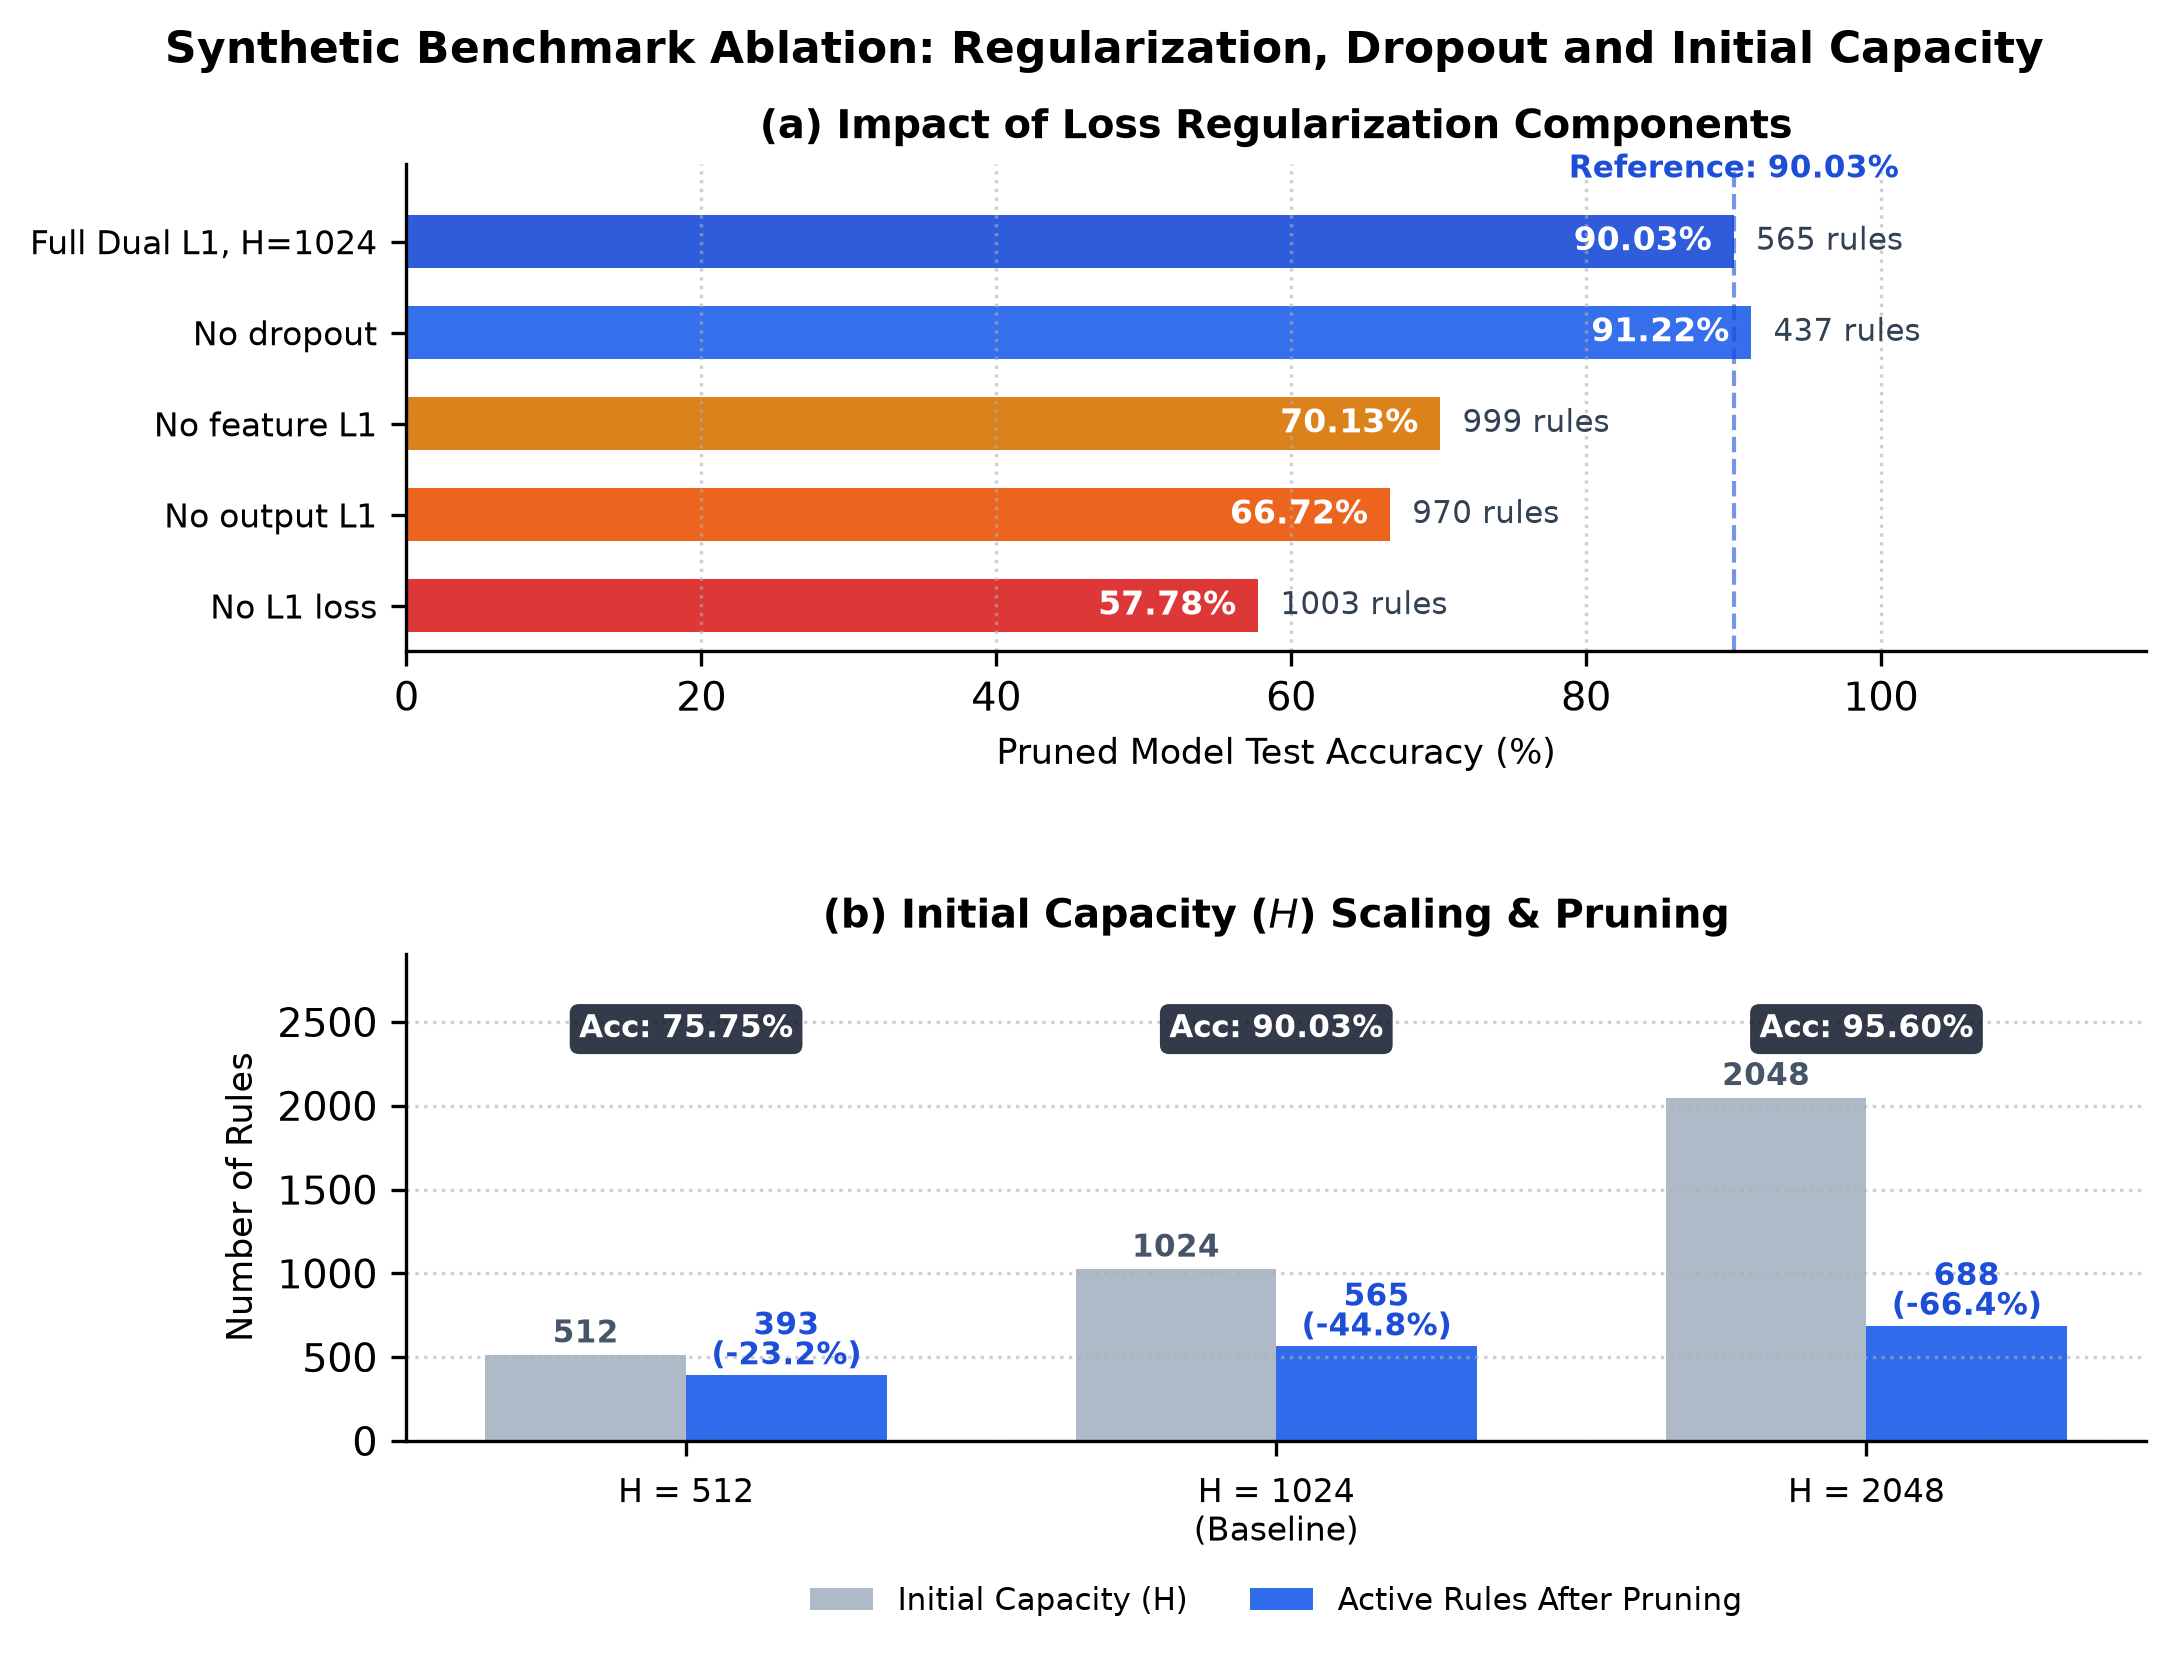

In [5]:
# ==============================================================================
# 3. PUBLICATION-QUALITY TWO-PANEL ABLATION FIGURE
# ==============================================================================
# The figure is produced at text width (7.16 in) with >= 7 pt type at print size,
# so no downscaling is needed in LaTeX (Elsevier artwork sizing).
fig = plt.figure(figsize=(7.16, 5.6), dpi=300)
gs = fig.add_gridspec(
    2, 1, height_ratios=[1.0, 1.0], hspace=0.62,
    left=0.175, right=0.985, top=0.905, bottom=0.145,
)

# ------------------------------------------------------------------------------
# Panel (a): Regularization and dropout ablation
# ------------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_title(
    r"$\mathbf{(a)}$ Impact of Loss Regularization Components",
    fontsize=9.5, fontweight="bold", pad=6,
)

reg_df = df_ablation_synthetic[
    df_ablation_synthetic["Group"] == "regularization"
].reset_index(drop=True)
reg_accs = reg_df["Test Acc (%)"].to_numpy(dtype=float)
reg_colors = ["#1D4ED8", "#2563EB", "#D97706", "#EA580C", "#DC2626"][: len(reg_df)]

# Short axis labels: full LaTeX names do not fit the column at 7 pt.
SHORT_LABELS = {
    "SCORE-Net (Full Dual $L_1$, H=1024)": "Full Dual L1, H=1024",
    "No Dropout ($p = 0.0$)": "No dropout",
    "No Feature $L_1$ ($\\lambda_1 = 0$)": "No feature L1",
    "No Output $L_1$ ($\\lambda_2 = 0$)": "No output L1",
    "No $L_1$ Loss ($\\lambda_1 = \\lambda_2 = 0$)": "No L1 loss",
}
short_names = [SHORT_LABELS[v] for v in reg_df["Variant"]]

y_pos = np.arange(len(reg_df))
bars = ax1.barh(
    y_pos, reg_accs, color=reg_colors, height=0.58, edgecolor="none", alpha=0.92
)
ax1.axvline(
    baseline_acc, color="#1D4ED8", linestyle="--", linewidth=1.0, alpha=0.6,
)

for bar, acc, (_, row) in zip(bars, reg_accs, reg_df.iterrows()):
    ax1.text(
        bar.get_width() - 1.5, bar.get_y() + bar.get_height() / 2,
        f"{acc:.2f}%", ha="right", va="center", color="white",
        fontweight="bold", fontsize=8.0,
    )
    ax1.text(
        bar.get_width() + 1.5, bar.get_y() + bar.get_height() / 2,
        f"{int(row['Pruned Rules (H*)'])} rules", ha="left", va="center",
        color="#334155", fontsize=7.5,
    )

ax1.set_yticks(y_pos)
ax1.set_yticklabels(short_names, fontsize=8.0)
ax1.invert_yaxis()
ax1.set_ylim(len(reg_df) - 0.5, -0.85)
ax1.text(
    baseline_acc, -0.62, f"Reference: {baseline_acc:.2f}%",
    ha="center", va="bottom", fontsize=7.5, color="#1D4ED8", fontweight="bold",
)
ax1.set_xlim(0, 118)
ax1.set_xlabel("Pruned Model Test Accuracy (%)", fontsize=8.5)
ax1.grid(axis="x", linestyle=":", alpha=0.6)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# ------------------------------------------------------------------------------
# Panel (b): Initial capacity scaling
# ------------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])
ax2.set_title(
    r"$\mathbf{(b)}$ Initial Capacity ($H$) Scaling & Pruning",
    fontsize=9.5, fontweight="bold", pad=6,
)

cap_df = df_ablation_synthetic[
    (df_ablation_synthetic["Group"] == "capacity")
    | df_ablation_synthetic["Is Reference"]
].sort_values("Initial H").reset_index(drop=True)
cap_inits = cap_df["Initial H"].to_numpy(dtype=int)
cap_finals = cap_df["Pruned Rules (H*)"].to_numpy(dtype=int)
cap_accs = cap_df["Test Acc (%)"].to_numpy(dtype=float)

cap_labels = []
for _, row in cap_df.iterrows():
    H = int(row["Initial H"])
    cap_labels.append(f"H = {H}\n(Baseline)" if row["Is Reference"] else f"H = {H}")

x_pos = np.arange(len(cap_df))
w_bar = 0.34
bar1 = ax2.bar(
    x_pos - w_bar / 2, cap_inits, width=w_bar, color="#94A3B8",
    label="Initial Capacity (H)", alpha=0.75,
)
bar2 = ax2.bar(
    x_pos + w_bar / 2, cap_finals, width=w_bar, color="#2563EB",
    label="Active Rules After Pruning", alpha=0.95,
)

max_cap = float(max(cap_inits.max(), cap_finals.max()))
badge_y = max_cap * 1.20
for i, (b1, b2, init_val, final_val, acc) in enumerate(
    zip(bar1, bar2, cap_inits, cap_finals, cap_accs)
):
    ax2.text(
        b1.get_x() + b1.get_width() / 2, init_val + 0.015 * max_cap, f"{init_val}",
        ha="center", va="bottom", fontsize=7.5, color="#475569", fontweight="bold",
    )
    prune_pct = (1.0 - final_val / init_val) * 100.0
    ax2.text(
        b2.get_x() + b2.get_width() / 2, final_val + 0.015 * max_cap,
        f"{final_val}\n(-{prune_pct:.1f}%)",
        ha="center", va="bottom", fontsize=7.5, color="#1D4ED8",
        fontweight="bold", linespacing=1.0,
    )
    ax2.text(
        x_pos[i], badge_y, f"Acc: {acc:.2f}%",
        ha="center", va="center", fontsize=7.5, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="#0F172A", edgecolor="none", alpha=0.85),
    )

ax2.set_xticks(x_pos)
ax2.set_xticklabels(cap_labels, fontsize=8.0, linespacing=1.2)
ax2.set_ylim(0, max_cap * 1.42)
ax2.set_ylabel("Number of Rules", fontsize=8.5)
ax2.legend(
    loc="upper center", bbox_to_anchor=(0.5, -0.24),
    ncol=2, frameon=False, fontsize=7.5,
)
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

fig.suptitle(
    "Synthetic Benchmark Ablation: Regularization, Dropout and Initial Capacity",
    fontweight="bold", fontsize=10.5, y=0.985,
)
save_figure(fig, "fig_ablation_synthetic")
plt.show()

In [6]:
# ==============================================================================
# 4. ABLATION TABLE (DYNAMIC LATEX)
# ==============================================================================
def _tex_pct(value, decimals=1, bold=False):
    text = f"{value:.{decimals}f}\\%"
    return f"\\textbf{{{text}}}" if bold else text


def _ablation_tex_row(row, label, best_acc, best_rules):
    is_ref = bool(row["Is Reference"])
    is_best = abs(float(row["Test Acc (%)"]) - best_acc) < 1e-9

    if is_ref:
        delta = r"\textit{Baseline}"
    else:
        delta = f"{float(row['Delta Acc (%)']):+.2f}\\%"

    rules = int(row["Pruned Rules (H*)"])
    rules_tex = f"\\textbf{{{rules}}}" if rules == best_rules else str(rules)

    return (
        f"{label} & {int(row['Initial H'])} & {rules_tex} & "
        f"{_tex_pct(row['Rule Pruning (%)'])} & "
        f"{_tex_pct(row['Feat Sparsity (%)'])} & "
        f"{float(row['Avg Feats/Rule']):.1f} & "
        f"{_tex_pct(row['Test Acc (%)'], 2, bold=is_ref or is_best)} & {delta} \\\\"
    )


reg_rows = df_ablation_synthetic[
    df_ablation_synthetic["Group"] == "regularization"
].reset_index(drop=True)
cap_rows = df_ablation_synthetic[
    (df_ablation_synthetic["Group"] == "capacity")
    | df_ablation_synthetic["Is Reference"]
].sort_values("Initial H").reset_index(drop=True)
best_cap_acc = float(cap_rows["Test Acc (%)"].max())

latex_lines = [
    r"\begin{table*}[t]",
    r"\centering",
    (
        r"\caption{Ablation study on the multi-class Synthetic benchmark "
        r"(" + str(split_syn.n_classes) + r" classes, " + str(split_syn.n_features)
        + r" features). We evaluate the impact of individual regularization "
        r"components (Dual $L_1$ loss vs. single/no $L_1$, Dropout) and initial "
        r"model capacity ($H$) on test accuracy, rule pruning efficiency, and "
        r"rule interpretability.}"
    ),
    r"\label{tab:ablation_synthetic}",
    r"\small",
    r"\begin{tabular}{l ccc ccc c}",
    r"\toprule",
    r"\textbf{Ablation Variant} & \textbf{Initial $H$} & \textbf{Pruned $H^*$} & "
    r"\textbf{Pruning (\%)} & \textbf{Feat. Sparsity (\%)} & "
    r"\textbf{Avg. Feat/Rule} & \textbf{Test Acc. (\%)} & \textbf{$\Delta$ Acc. (\%)} \\",
    r"\midrule",
    (
        r"\multicolumn{8}{l}{\textit{\textbf{Loss Regularization and Dropout "
        r"Ablation ($H_{\text{init}}=" + str(baseline_H) + r"$)}}} \\"
    ),
]
best_reg_rules = int(reg_rows["Pruned Rules (H*)"].max())
for _, row in reg_rows.iterrows():
    latex_lines.append(
        _ablation_tex_row(row, row["Variant"], baseline_acc, best_reg_rules)
    )
latex_lines.extend([
    r"\midrule",
    r"\multicolumn{8}{l}{\textit{\textbf{Initial Capacity Scaling ($H$)}}} \\",
])
best_cap_rules = int(cap_rows["Pruned Rules (H*)"].max())
for _, row in cap_rows.iterrows():
    latex_lines.append(
        _ablation_tex_row(
            row, row["Capacity TeX Label"], best_cap_acc, best_cap_rules
        )
    )
latex_lines.extend([
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table*}",
])

latex_ablation = "\n".join(latex_lines)
print(latex_ablation)

\begin{table*}[t]
\centering
\caption{Ablation study on the multi-class Synthetic benchmark (20 classes, 30 features). We evaluate the impact of individual regularization components (Dual $L_1$ loss vs. single/no $L_1$, Dropout) and initial model capacity ($H$) on test accuracy, rule pruning efficiency, and rule interpretability.}
\label{tab:ablation_synthetic}
\small
\begin{tabular}{l ccc ccc c}
\toprule
\textbf{Ablation Variant} & \textbf{Initial $H$} & \textbf{Pruned $H^*$} & \textbf{Pruning (\%)} & \textbf{Feat. Sparsity (\%)} & \textbf{Avg. Feat/Rule} & \textbf{Test Acc. (\%)} & \textbf{$\Delta$ Acc. (\%)} \\
\midrule
\multicolumn{8}{l}{\textit{\textbf{Loss Regularization and Dropout Ablation ($H_{\text{init}}=1024$)}}} \\
SCORE-Net (Full Dual $L_1$, H=1024) & 1024 & 565 & 44.8\% & 78.0\% & 6.6 & \textbf{90.03\%} & \textit{Baseline} \\
No Dropout ($p = 0.0$) & 1024 & 437 & 57.3\% & 71.5\% & 8.5 & 91.22\% & +1.19\% \\
No Feature $L_1$ ($\lambda_1 = 0$) & 1024 & 999 & 2.4\% & 87.8\%

---
## Part 2: Proposition 1 (Exact Bias Shifting) vs. Naive Pruning

For a structurally empty rule, the $W_f$ row is entirely zero. The rule's input-dependent projection is therefore always $h=0$, and its activation is constant for all $x$:

$$a_h(x) = \frac{\max(0,\, w_h - |c_h|)}{w_h}.$$

If this constant baseline effect is not transferred to the output bias when the rule is removed, the model logits shift systematically. Proposition 1 adds the baseline contribution of the pruned rules to the bias,

$$\Delta b_o = \sum_{h \in \mathcal{H}_{\text{pruned}}} W_o[:, h] \, a_h(0)$$

which guarantees **exact** preservation of the output. The experiment below compares Proposition 1 with naive pruning on the four benchmark datasets and the protected-attribute-free COMPAS variant; both methods remove only structurally empty rules, so the bias shift is the only variable.

In [7]:
# ==============================================================================
# 5. VALIDATING PROPOSITION 1 ON FOUR BENCHMARK DATASETS AND THE PROTECTED-ATTRIBUTE-FREE COMPAS VARIANT
# ==============================================================================
def _drift_stats(orig_logits, orig_preds, logits, preds):
    diff = (orig_logits - logits).abs()
    return {
        "max_drift": float(diff.max().item()),
        "mean_drift": float(diff.mean().item()),
        "fidelity": float((orig_preds == preds).float().mean().item()) * 100.0,
    }


theorem_rows = []

for key, spec in DATASETS.items():
    split = load_splits(key)
    X_test = split.X_test
    y_test = split.y_test

    original = load_checkpoint(spec.final_checkpoint, device=device)
    H_init = int(original.H)

    with torch.no_grad():
        orig_logits = original(X_test)
        orig_preds = orig_logits.argmax(dim=1)
        orig_acc = float((orig_preds == y_test).float().mean().item()) * 100.0

    model_thm1 = prune_structurally(copy.deepcopy(original), shift_bias=True)
    model_naive = prune_structurally(copy.deepcopy(original), shift_bias=False)

    with torch.no_grad():
        thm1_logits = model_thm1(X_test)
        thm1_preds = thm1_logits.argmax(dim=1)
        thm1_acc = float((thm1_preds == y_test).float().mean().item()) * 100.0

        naive_logits = model_naive(X_test)
        naive_preds = naive_logits.argmax(dim=1)
        naive_acc = float((naive_preds == y_test).float().mean().item()) * 100.0

    thm1_stats = _drift_stats(orig_logits, orig_preds, thm1_logits, thm1_preds)
    naive_stats = _drift_stats(orig_logits, orig_preds, naive_logits, naive_preds)

    theorem_rows.append({
        "Dataset": spec.display_name,
        "Initial H": H_init,
        "Eliminated Rules": H_init - int(model_thm1.H),
        "Thm1 Max Drift": thm1_stats["max_drift"],
        "Thm1 Mean Drift": thm1_stats["mean_drift"],
        "Thm1 Acc (%)": thm1_acc,
        "Thm1 Fidelity (%)": thm1_stats["fidelity"],
        "Naive Max Drift": naive_stats["max_drift"],
        "Naive Mean Drift": naive_stats["mean_drift"],
        "Naive Acc (%)": naive_acc,
        "Naive Fidelity (%)": naive_stats["fidelity"],
        "Drift Penalty (%)": orig_acc - naive_acc,
    })

df_theorem1 = pd.DataFrame(theorem_rows)

print("=== PROPOSITION 1 (EXACT BIAS SHIFTING) EMPIRICAL VALIDATION ===")
print(
    df_theorem1[[
        "Dataset", "Eliminated Rules", "Thm1 Max Drift", "Thm1 Acc (%)",
        "Thm1 Fidelity (%)", "Naive Max Drift", "Naive Acc (%)",
        "Naive Fidelity (%)", "Drift Penalty (%)",
    ]].to_string(index=False)
)

[Data] Loading German Credit Risk...
-> German Credit ready: train shape: (800, 48), Test Shape: (100, 48), feature count: 48, Val Shape: (100, 48)
[Data] Loading UCI Adult Census Income...


-> UCI Adult ready: train shape: (32559, 97), Test Shape: (9045, 97), feature count: 97, Val Shape: (3618, 97)
=== PROPOSITION 1 (EXACT BIAS SHIFTING) EMPIRICAL VALIDATION ===
                         Dataset  Eliminated Rules  Thm1 Max Drift  Thm1 Acc (%)  Thm1 Fidelity (%)  Naive Max Drift  Naive Acc (%)  Naive Fidelity (%)  Drift Penalty (%)
                          COMPAS                27    1.192093e-07     66.320169              100.0         0.364679      57.311159           62.439364           9.009010
COMPAS (no protected attributes)                29    8.940697e-08     66.666669              100.0         0.227365      58.073455           63.548166           8.593214
                   German Credit                12    4.768372e-07     75.000000              100.0         0.248216      73.000002           92.000002           1.999998
                       UCI Adult                21    7.152557e-07     85.605305              100.0         0.154280      85.129905         

In [8]:
# ==============================================================================
# WRITE PROPOSITION 1 RESULTS TO CACHE (THE TABLE NOTEBOOK READS THEM HERE)
# ==============================================================================
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
theorem_csv = RESULTS_DIR / "theorem1_bias_shifting.csv"
df_theorem1.to_csv(theorem_csv, index=False)
print(f"Saved: {theorem_csv}")


Saved: /home/ahmet/Projects/ScoreNetSingle/results/theorem1_bias_shifting.csv


In [9]:
# ==============================================================================
# 6. PROPOSITION 1 TABLE (DYNAMIC LATEX)
# ==============================================================================
def _sci_tex(value, bold=True):
    mantissa, exponent = f"{value:.2e}".split("e")
    body = f"{mantissa} \\times 10^{{{int(exponent)}}}"
    return f"$\\mathbf{{{body}}}$" if bold else f"${body}$"


def _fidelity_tex(value):
    text = f"{value:.1f}\\%"
    return f"$\\mathbf{{{text}}}$" if value >= 99.999 else text


max_thm1_drift = float(df_theorem1["Thm1 Max Drift"].max())
max_penalty = float(df_theorem1["Drift Penalty (%)"].max())
min_thm1_fidelity = float(df_theorem1["Thm1 Fidelity (%)"].min())

if max_penalty > 0.005:
    penalty_sentence = (
        f"Naive pruning induces up to a $+{max_penalty:.2f}\\%$ test accuracy penalty."
    )
else:
    penalty_sentence = "Naive pruning's accuracy penalty is negligible on these checkpoints."

latex_thm1_lines = [
    r"\begin{table}[t]",
    r"\centering",
    (
        r"\caption{Empirical validation of Proposition~\ref{prop:bias_shifting} (Exact Bias Shifting) on "
        r"the four benchmark datasets and the protected-attribute-free COMPAS variant. Only structurally empty rules are removed, so the "
        r"sole difference between the two methods is the bias shift. Proposition 1 "
        r"preserves the model output up to floating-point and threshold effects (maximum drift "
        + _sci_tex(max_thm1_drift, bold=False)
        + r", minimum fidelity "
        + f"{min_thm1_fidelity:.1f}\\%"
        + r"). "
        + penalty_sentence
        + r"}"
    ),
    r"\label{tab:theorem1_bias_shifting}",
    r"\small",
    r"\begin{tabular}{l c cc cc c}",
    r"\toprule",
    r"\multirow{2}{*}{\textbf{Dataset}} & \multirow{2}{*}{\textbf{Pruned Rules}} & "
    r"\multicolumn{2}{c}{\textbf{Proposition 1 (Exact Shift)}} & "
    r"\multicolumn{2}{c}{\textbf{Naive Pruning (No Shift)}} & "
    r"\multirow{2}{*}{\textbf{Drift Penalty}} \\",
    r"\cmidrule(lr){3-4} \cmidrule(lr){5-6}",
    r" & & \textbf{Max Drift} & \textbf{Fidelity} & \textbf{Max Drift} & "
    r"\textbf{Fidelity} & \\",
    r"\midrule",
]

for _, row in df_theorem1.iterrows():
    latex_thm1_lines.append(
        f"{row['Dataset']} & {int(row['Eliminated Rules'])} / {int(row['Initial H'])} & "
        f"{_sci_tex(row['Thm1 Max Drift'])} & "
        f"{_fidelity_tex(row['Thm1 Fidelity (%)'])} & "
        f"{float(row['Naive Max Drift']):.4f} & "
        f"{_fidelity_tex(row['Naive Fidelity (%)'])} & "
        f"{float(row['Drift Penalty (%)']):+.2f}\\% \\\\"
    )

latex_thm1_lines.extend([
    r"\bottomrule",
    r"\end{tabular}",
    r"\end{table}",
])

latex_thm1 = "\n".join(latex_thm1_lines)
print(latex_thm1)

\begin{table}[t]
\centering
\caption{Empirical validation of Proposition~\ref{prop:bias_shifting} (Exact Bias Shifting) on the four benchmark datasets and the protected-attribute-free COMPAS variant. Only structurally empty rules are removed, so the sole difference between the two methods is the bias shift. Proposition 1 preserves the model output up to floating-point and threshold effects (maximum drift $5.72 \times 10^{-6}$, minimum fidelity 100.0\%). Naive pruning induces up to a $+9.01\%$ test accuracy penalty.}
\label{tab:theorem1_bias_shifting}
\small
\begin{tabular}{l c cc cc c}
\toprule
\multirow{2}{*}{\textbf{Dataset}} & \multirow{2}{*}{\textbf{Pruned Rules}} & \multicolumn{2}{c}{\textbf{Proposition 1 (Exact Shift)}} & \multicolumn{2}{c}{\textbf{Naive Pruning (No Shift)}} & \multirow{2}{*}{\textbf{Drift Penalty}} \\
\cmidrule(lr){3-4} \cmidrule(lr){5-6}
 & & \textbf{Max Drift} & \textbf{Fidelity} & \textbf{Max Drift} & \textbf{Fidelity} & \\
\midrule
COMPAS & 27 / 32 & $\mathb

## Validation notes

* **Panel (a)** shows only the regularization/dropout variants, while **panel (b)** shows initial capacity. In both panels, rule counts and accuracies are derived from the checkpoints at runtime.
* The **Proposition 1 table** uses structural pruning only. This ensures that the bias shift is the only difference between the two methods and prevents empirical dead-rule cleanup from masking the result.
* Proposition 1's maximum logit drift stays at float32 precision ($\sim 10^{-6}$), whereas naive pruning produces noticeable drift and accuracy loss.
* The figure is saved as `paper/neurocomputing/figures/fig_ablation_synthetic.pdf` and `.png`. Tables are printed as dynamic LaTeX; no numbers are copied into the paper by hand.